# Heading queries: draw each photo several times, one per heading guess

**This is a record test, not a tuning run.** The settings below are the ones from `tests/Parameter_Test` and the Patch v0.5.6 analysis; nothing here should be tuned on these photos.

**Idea** (Patch v0.5.6, Sec. 2): the yaw in the metadata is a few degrees off for some photos, and a few degrees are enough to lose the place in the coarse search (12 of 100 photos were lost that way). The coarse search draws the photo north-up at *one* heading. Here one photo goes in, is **multiplied into several queries** (heading -10 to +10 degrees in steps of 2.5, 9 queries), every query goes through the pipeline (render, maps, coarse search, DINO layer, LoFTR on its own drawing), and the answer is chosen among the candidates of all queries.

**How it runs.** Like `Single_Image_Run.ipynb`, one photo at a time goes through the pipeline. The pipeline is built once. The three random seeds only choose which photos are tested (stratified over the three height groups); photos chosen by more than one seed are run once. Because every query's candidates are kept, **all variants are scored from the same run**: the plain query alone, 3 headings, 5 headings, all 9. Nothing is run twice.

**What is measured, seed by seed, side by side**
* **score (/60)** and **wrong answers** (the -20 point ones)
* **target in candidates**: some candidate lies within `FOUND_SIGMA` of the truth (the recall the queries bring)
* **wrong candidate reaches bar**: a candidate that is *not* near the truth still has at least `MIN_INLIERS` inliers. This is the false-flag risk: more queries means more candidates, so more chances for a wrong place to get through. It must not grow.
* seconds per photo (the price of the extra queries)

**Read it with care.** A few photos per seed are noisy (one photo is worth about 0.6 points per 100). Look for the same direction in all three seeds, and for the false-flag number staying near zero.

# Part 1 · Settings

In [1]:
import os, sys, math, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos; the map comes from src/header/map_source.py) or "nudt" (Changsha test photos)
MAP = "new"                 # base map of the official photos: "new" (both scenes), "new_931", "new_921" or "old"
MAP_MARGIN_M = None         # metres of map kept around the photos (None = 6000 from map_source.py; the search disc is 5500 m)
POOL_PHOTOS = 500           # photos loaded once; the seeds pick from them
SEEDS = [11, 22, 33]        # three random seeds, side by side: each picks its own photos
N_PER_SEED = 150            # photos per seed (a multiple of 3: the same number from each height group). 150 x 3 seeds covers about 330 of the ~500 photos, so the seeds overlap and the 'all' column is the one to trust for the size of the gain
FOUND_SIGMA = 4.0           # a place counts as found when it is within this many sigma of the truth

# the queries: every photo is drawn once per (heading, scale factor)
HEADINGS = [-10.0, -7.5, -5.0, -2.5, 0.0, 2.5, 5.0, 7.5, 10.0]   # degrees added to the yaw (Patch v0.5.6: the needed corrections are within +-10)
SCALE_FACTORS = [1.0]       # the projection scale is multiplied by each of these; [1.0, 1.05] doubles the queries (level 7 photos preferred 1.05)

# per query: the same pipeline as Single_Image_Run
COARSE = "edge_zncc"        # "edge_zncc" (one map, cheap: the patch recommends it for the hypotheses) or "fused" (six maps, about 9 times that cost)
USE_SEMANTIC_LAYER = True   # DINO re-orders the K coarse places of each query
K_PER_QUERY = 50            # K: places the coarse search returns for each query
M_PER_QUERY = 10            # M: places of each query that go to LoFTR (5 gave the same score as 25 on the development photos)
DINO_WEIGHT = None          # None = 100 (DINO decides the order inside the K)
GAMMA = 1.0                 # the answer is the candidate with the most  inliers + GAMMA * (DINO z-score) among ALL queries
MATCHER = "loftr_minima"    # "lightglue", "loftr_minima" or "roma_minima"
MATCHER_CONFIDENCE = 0.21   # LoFTR only: matches below this confidence are dropped (0.2 = kornia's default; lower lets weak, possibly false matches through)
LOFTR_COARSE_THRESHOLD = 0.21  # LoFTR only: its own cut on the coarse match probability
RANSAC_PIXELS = None        # None = 3.0
MIN_INLIERS = 8             # answer bar

# the variants that are scored from the same run: name -> (headings, scale factors); a variant needs all its queries to exist
VARIANTS = {
    "plain (heading 0)": ([0.0], [1.0]),
    "3 headings (-5, 0, +5)": ([-5.0, 0.0, 5.0], [1.0]),
    "5 headings (step 5)": ([-10.0, -5.0, 0.0, 5.0, 10.0], [1.0]),
    "all headings": (HEADINGS, [1.0]),
    "all headings x all scales": (HEADINGS, SCALE_FACTORS),
}
# the same candidates are also scored with a cost for the heading: each candidate pays  penalty * |heading|  inliers (inliers per degree) when the best one is chosen.
# 0 = the best candidate wins whatever its heading (the variants above). These are scored on the "all headings" queries from the same run, nothing is run twice.
HEADING_PENALTIES = [0.25, 0.5, 1.0]     # 0.5 means a candidate 10 degrees off needs 5 more inliers than one at 0 degrees
plt.rcParams["figure.dpi"] = 90

assert len(SEEDS) >= 1 and N_PER_SEED >= 3, "need at least one seed and 3 photos per seed"
assert 0.0 in HEADINGS and 1.0 in SCALE_FACTORS, "the plain query (heading 0, scale factor 1) is the baseline and must be in the lists"

# Part 2 · Set up once

The pipeline with its queries: map, features, DINO and LoFTR are loaded once for all seeds.

In [2]:
from heading_query_pipeline import HeadingQueryPipeline        # first import: it saves the development-set settings before NUDT changes them
from header import settings
from header.sampling import pick_sample_ids
from header.scoring import final_score
from coarse_search.heading_queries import query_list
from train.checks.heading_results import variant_ids, query_rows, variant_rows, summarise

pipeline = HeadingQueryPipeline(DATA, COARSE, semantic_layer=USE_SEMANTIC_LAYER, semantic_decision=True, gamma=GAMMA,
                                k_peaks=K_PER_QUERY, m_fine=M_PER_QUERY, matcher=MATCHER, min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS,
                                matcher_confidence=MATCHER_CONFIDENCE, satellite=MAP, map_margin_m=MAP_MARGIN_M,
                                loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD, dino_weight=DINO_WEIGHT,
                                headings=HEADINGS, scale_factors=SCALE_FACTORS)
start = time.time()
pipeline.setup(POOL_PHOTOS, 7)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)

test_set = pipeline.test_set
camera = pipeline.camera

variants = {}
for name, (headings, factors) in VARIANTS.items():
    if all(h in HEADINGS for h in headings) and all(f in SCALE_FACTORS for f in factors):
        variants[name] = variant_ids(pipeline.queries, headings, factors)
    else:
        print("variant %r skipped: its headings or scale factors are not all among the queries" % name)
penalties = {}
for penalty in HEADING_PENALTIES:
    name = "all headings, penalty %.2g per degree" % penalty
    variants[name] = variant_ids(pipeline.queries, HEADINGS, [1.0])
    penalties[name] = penalty
print({name: len(ids) for name, ids in variants.items()}, "queries per variant")

level 3: 0.85 m/pixel, picture 16378 x 16005, map coverage 100%
level 4: 1.20 m/pixel, picture 11581 x 11317, map coverage 100%
level 5: 1.70 m/pixel, picture 8189 x 8002, map coverage 100%
level 6: 2.40 m/pixel, picture 5790 x 5658, map coverage 100%
level 7: 3.39 m/pixel, picture 4094 x 4001, map coverage 100%
map store ready, took 109 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 124.7 s
data: official | 379 photos available | zoom levels [3, 4, 5, 6, 7]
photos: official | map: new
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=10) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.21 | LoFTR coarse threshold 0.21, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
device: cuda
queries per photo: 9 (headings [-10.0, -7.5, -5.0, -2.5, 0.0, 2.5, 5.0, 7.5, 10.0], scale factors [1.0]); K and M are per query
{'plain (heading 0)': 1, '3 headings (-5, 0, +5)': 3, '5 headings (step 5)': 5, 'all headings': 9, 'all headings x all scales': 9, 'all headings, penalty 0.25 per degree': 9, 'all headings, penalty 0.5 per degree': 9, 'all headings, penalty 1 per degree': 9} queries per variant


# Part 3 · The photos of each seed

Each seed picks `N_PER_SEED` photos, the same number from each height group. Photos that more than one seed picks are run once.

In [3]:
samples = {}
for seed in SEEDS:
    samples[seed] = [int(i) for i in pick_sample_ids(test_set.flight_of_frame, N_PER_SEED, seed)]
all_photos = sorted(set(i for ids in samples.values() for i in ids))
rows = []
for seed in SEEDS:
    heights = [test_set.items[i]["rel_height"] for i in samples[seed]]
    shared = len(set(samples[seed]) & set(i for other in SEEDS if other != seed for i in samples[other]))
    rows.append(dict(seed=seed, photos=len(samples[seed]), also_in_another_seed=shared, min_height=min(heights), median_height=float(np.median(heights)), max_height=max(heights)))
display(pd.DataFrame(rows).round(0))
print("%d different photos to run in all, %d queries each = %d passes through the pipeline" % (len(all_photos), len(pipeline.queries), len(all_photos) * len(pipeline.queries)))

,seed,photos,also_in_another_seed,min_height,median_height,max_height
0,11,150,98,100.0,170.0,351.0
1,22,150,102,100.0,170.0,351.0
2,33,150,105,100.0,170.0,351.0


273 different photos to run in all, 9 queries each = 2457 passes through the pipeline


# Part 4 · One photo at a time, each multiplied into its queries

For every photo: all queries run to the fine stage, then every variant decides from its own subset of the queries. Only small tables are kept (the candidates are not stored).

In [4]:
import torch
from header.scoring import points_for_error

photo_query_rows = {}       # photo -> rows of query_rows
photo_variant_rows = {}     # photo -> rows of variant_rows
failures = []
loop_start = time.time()
for position, index in enumerate(all_photos):
    item = test_set.items[index]
    truth = test_set.truths[index]
    sigma = test_set.sigmas[index]
    try:
        found = None
        for attempt in range(3):                        # the GPU may be shared with other notebooks: on a memory error free the cache, wait and try again
            try:
                found = pipeline.run_queries(item, test_set.priors[index])
                break
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                time.sleep(5)
        if found is None:
            raise MemoryError("GPU out of memory three times in a row (close the other notebooks that use the GPU)")
        photo_query_rows[index] = query_rows(found, truth, sigma, FOUND_SIGMA, MIN_INLIERS)
        photo_variant_rows[index] = variant_rows(pipeline, found, variants, truth, sigma, item["rel_height"], camera.fx, FOUND_SIGMA, MIN_INLIERS, penalties)
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
    if (position + 1) % 5 == 0 or position + 1 == len(all_photos):
        done = time.time() - loop_start
        print("photo %d/%d | %.0f s so far | %.1f s per photo" % (position + 1, len(all_photos), done, done / (position + 1)))
print("%d photos done in %.0f s (%d failed)" % (len(photo_variant_rows), time.time() - loop_start, len(failures)))
assert len(failures) <= 0.05 * len(all_photos), "%d of %d photos failed: the tables below would describe only the photos that survived (see the failures list)" % (len(failures), len(all_photos))

photo 5/273 | 33 s so far | 6.5 s per photo
photo 10/273 | 62 s so far | 6.2 s per photo
photo 15/273 | 89 s so far | 5.9 s per photo
photo 20/273 | 121 s so far | 6.0 s per photo
photo 25/273 | 148 s so far | 5.9 s per photo
photo 30/273 | 178 s so far | 5.9 s per photo
photo 35/273 | 214 s so far | 6.1 s per photo
photo 40/273 | 243 s so far | 6.1 s per photo
photo 45/273 | 271 s so far | 6.0 s per photo
photo 50/273 | 304 s so far | 6.1 s per photo
photo 55/273 | 332 s so far | 6.0 s per photo
photo 60/273 | 365 s so far | 6.1 s per photo
photo 65/273 | 396 s so far | 6.1 s per photo
photo 70/273 | 432 s so far | 6.2 s per photo
photo 75/273 | 460 s so far | 6.1 s per photo
photo 80/273 | 487 s so far | 6.1 s per photo
photo 85/273 | 523 s so far | 6.2 s per photo
photo 90/273 | 552 s so far | 6.1 s per photo
photo 95/273 | 584 s so far | 6.1 s per photo
photo 100/273 | 615 s so far | 6.2 s per photo
photo 105/273 | 650 s so far | 6.2 s per photo
photo 110/273 | 676 s so far | 6.1 s

# Part 5 · The seeds side by side

One table per measure: rows are the variants, columns the three seeds and all photos together. Compare **within a column** (the same photos) and look for the same direction in every seed.

In [5]:
def photo_table(index):
    table = pd.DataFrame(photo_variant_rows[index])
    table.insert(0, "photo", index)
    table["height"] = test_set.items[index]["rel_height"]
    table["level"] = int(test_set.query_levels[index])
    return table

per_variant = pd.concat([photo_table(i) for i in sorted(photo_variant_rows)], ignore_index=True)
summary_rows = []
groups = [(str(seed), [i for i in samples[seed] if i in photo_variant_rows]) for seed in SEEDS] + [("all", sorted(photo_variant_rows))]
for label, photos in groups:
    for name in variants:
        part = per_variant[(per_variant["variant"] == name) & per_variant["photo"].isin(photos)]
        row = dict(seed=label, variant=name)
        row.update(summarise(part, FOUND_SIGMA))
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows)

for measure in ["score (/60)", "answered right", "wrong answers", "target in candidates", "wrong candidate reaches bar", "seconds per photo"]:
    print(measure)
    display(summary.pivot(index="variant", columns="seed", values=measure).reindex(list(variants)).round(3))

score (/60)


seed,11,22,33,all
variant,,,,
plain (heading 0),43.56,40.88,41.80,41.297
"3 headings (-5, 0, +5)",48.48,46.76,48.68,46.527
5 headings (step 5),50.08,48.36,50.28,47.846
all headings,50.88,50.20,51.32,49.736
all headings x all scales,50.88,50.20,51.32,49.736
"all headings, penalty 0.25 per degree",50.64,49.80,50.92,49.604
"all headings, penalty 0.5 per degree",50.08,49.24,50.76,49.297
"all headings, penalty 1 per degree",50.32,48.44,49.56,48.989


answered right


seed,11,22,33,all
variant,,,,
plain (heading 0),0.747,0.700,0.720,0.707
"3 headings (-5, 0, +5)",0.840,0.800,0.840,0.806
5 headings (step 5),0.867,0.827,0.867,0.828
all headings,0.880,0.860,0.887,0.861
all headings x all scales,0.880,0.860,0.887,0.861
"all headings, penalty 0.25 per degree",0.873,0.853,0.880,0.857
"all headings, penalty 0.5 per degree",0.867,0.847,0.880,0.853
"all headings, penalty 1 per degree",0.860,0.833,0.860,0.842


wrong answers


seed,11,22,33,all
variant,,,,
plain (heading 0),0,0,0,0
"3 headings (-5, 0, +5)",1,0,0,1
5 headings (step 5),1,0,0,1
all headings,1,0,0,1
all headings x all scales,1,0,0,1
"all headings, penalty 0.25 per degree",1,0,0,1
"all headings, penalty 0.5 per degree",1,0,0,1
"all headings, penalty 1 per degree",0,0,0,0


... (2 outputs left out)

wrong candidate reaches bar


seed,11,22,33,all
variant,,,,
plain (heading 0),0.000,0.000,0.000,0.000
"3 headings (-5, 0, +5)",0.013,0.000,0.007,0.007
5 headings (step 5),0.013,0.007,0.013,0.015
all headings,0.013,0.013,0.020,0.018
all headings x all scales,0.013,0.013,0.020,0.018
"all headings, penalty 0.25 per degree",0.013,0.013,0.020,0.018
"all headings, penalty 0.5 per degree",0.013,0.013,0.020,0.018
"all headings, penalty 1 per degree",0.013,0.013,0.020,0.018


seconds per photo


seed,11,22,33,all
variant,,,,
plain (heading 0),0.696,0.680,0.683,0.691
"3 headings (-5, 0, +5)",2.087,2.038,2.049,2.072
5 headings (step 5),3.481,3.397,3.414,3.455
all headings,6.263,6.115,6.146,6.218
all headings x all scales,6.263,6.115,6.146,6.218
"all headings, penalty 0.25 per degree",6.263,6.115,6.146,6.218
"all headings, penalty 0.5 per degree",6.263,6.115,6.146,6.218
"all headings, penalty 1 per degree",6.263,6.115,6.146,6.218


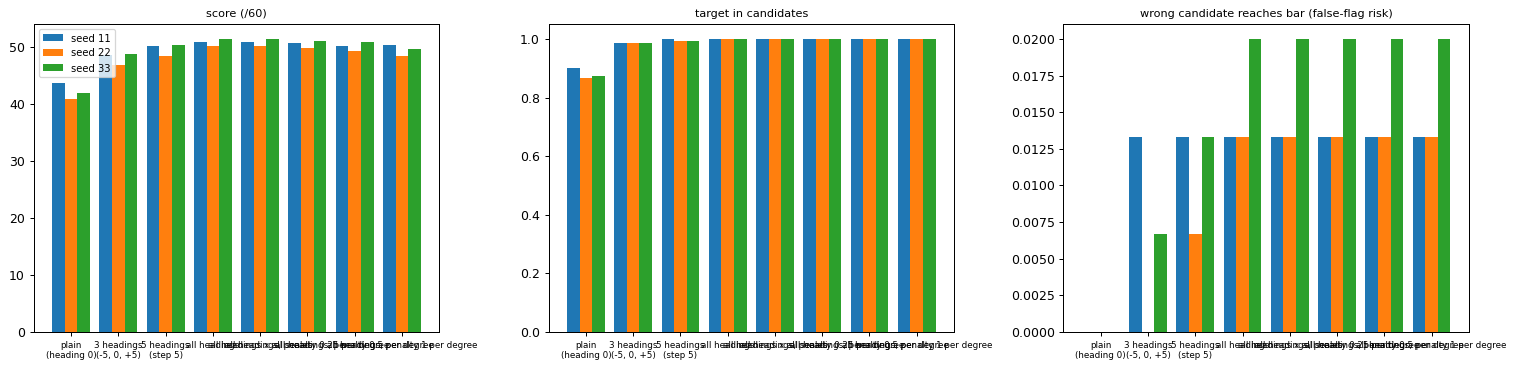

In [6]:
measures = [("score (/60)", "score (/60)"), ("target in candidates", "target in candidates"), ("wrong candidate reaches bar", "wrong candidate reaches bar (false-flag risk)")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
labels = [str(s) for s in SEEDS]
width = 0.8 / len(labels)
for axis, (measure, title) in zip(axes, measures):
    for k, label in enumerate(labels):
        part = summary[summary["seed"] == label].set_index("variant").reindex(list(variants))
        axis.bar(np.arange(len(variants)) + k * width, part[measure], width=width, label="seed " + label)
    axis.set_xticks(np.arange(len(variants)) + width * (len(labels) - 1) / 2)
    axis.set_xticklabels([n.replace(" (", "\n(") for n in variants], fontsize=7)
    axis.set_title(title, fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Part 6 · Which heading finds the place?

For each query heading: the share of photos where that query alone has a candidate within `FOUND_SIGMA` of the truth, and where that candidate reaches the bar. If the headings that rescue photos are spread over +-10 degrees, the search is doing its job; if only 0 ever finds anything, the extra queries are wasted.

In [7]:
per_query = []
for index in sorted(photo_query_rows):
    table = pd.DataFrame(photo_query_rows[index])
    table.insert(0, "photo", index)
    per_query.append(table)
per_query = pd.concat(per_query, ignore_index=True)
per_query["key"] = [("%+.1f" % h) + (" x%.2f" % f if len(SCALE_FACTORS) > 1 else "") for h, f in zip(per_query["heading"], per_query["scale_factor"])]
order = list(dict.fromkeys(per_query["key"]))
rows = []
for label, photos in groups:
    part = per_query[per_query["photo"].isin(photos)]
    found_by = part.groupby("key")["target_found"].mean().reindex(order)
    bar_by = part.groupby("key")["right_reaches_bar"].mean().reindex(order)
    rows.append(pd.DataFrame({"seed": label, "query": order, "target found": found_by.values, "right candidate reaches bar": bar_by.values}))
by_heading = pd.concat(rows, ignore_index=True)
print("share of photos where this query alone finds the place (columns: seeds)")
display(by_heading.pivot(index="query", columns="seed", values="target found").reindex(order).round(2))
print("share of photos where this query alone has the right candidate at the bar")
display(by_heading.pivot(index="query", columns="seed", values="right candidate reaches bar").reindex(order).round(2))

share of photos where this query alone finds the place (columns: seeds)


seed,11,22,33,all
query,,,,
-10.0,0.37,0.35,0.42,0.36
-7.5,0.58,0.61,0.63,0.59
-5.0,0.78,0.77,0.79,0.78
-2.5,0.91,0.91,0.90,0.90
+0.0,0.90,0.87,0.87,0.87
+2.5,0.81,0.78,0.79,0.78
+5.0,0.73,0.68,0.72,0.69
+7.5,0.53,0.53,0.55,0.50
+10.0,0.42,0.42,0.47,0.40


share of photos where this query alone has the right candidate at the bar


seed,11,22,33,all
query,,,,
-10.0,0.28,0.25,0.31,0.26
-7.5,0.47,0.45,0.50,0.46
-5.0,0.59,0.59,0.60,0.60
-2.5,0.71,0.69,0.73,0.71
+0.0,0.75,0.70,0.72,0.71
+2.5,0.67,0.63,0.68,0.65
+5.0,0.65,0.59,0.65,0.61
+7.5,0.43,0.43,0.41,0.41
+10.0,0.22,0.25,0.29,0.25


# Part 7 · Photos the extra queries changed

Comparing "all headings" with the plain query on every photo: the photos that gained points, the photos that lost points (a wrong answer that came in through an extra query would show here), and the heading that won.

all headings against plain (heading 0) on 273 photos: 46 gained (+427 points), 7 lost (-43 points), 220 unchanged
photos that gained


,height,plain points,all headings points,plain answered,multi answered,plain target found,multi target found,winning heading,multi error (sigma),difference
photo,,,,,,,,,,
3,146.1,0,10,False,True,False,True,7.5,0.74,10
12,350.2,6,10,True,True,True,True,-2.5,0.75,4
18,350.3,0,6,False,True,False,True,-2.5,1.62,6
31,120.5,0,10,False,True,False,True,5.0,0.12,10
44,300.3,0,10,False,True,True,True,-2.5,0.63,10
59,150.3,0,10,False,True,False,True,-7.5,0.47,10
66,129.0,0,10,False,True,True,True,-2.5,0.59,10
72,104.9,0,10,False,True,True,True,2.5,0.96,10
74,150.2,0,10,False,True,True,True,5.0,0.63,10


photos that lost (look at these first)


,height,plain points,all headings points,plain answered,multi answered,plain target found,multi target found,winning heading,multi error (sigma),difference
photo,,,,,,,,,,
19,170.2,10,6,True,True,True,True,2.5,1.02,-4
60,280.3,10,6,True,True,True,True,-2.5,1.08,-4
63,219.9,10,6,True,True,True,True,-2.5,1.12,-4
95,350.0,10,6,True,True,True,True,-2.5,1.07,-4
213,350.5,6,3,True,True,True,True,-5.0,2.88,-3
307,350.1,10,6,True,True,True,True,5.0,1.35,-4
347,100.6,0,-20,False,True,True,True,5.0,189.43,-20


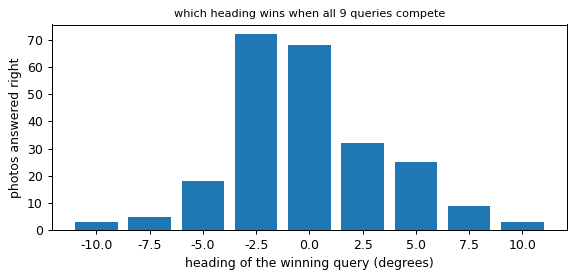

In [8]:
plain_name = "plain (heading 0)"
multi_name = "all headings" if "all headings" in variants else list(variants)[-1]
plain = per_variant[per_variant["variant"] == plain_name].set_index("photo")
multi = per_variant[per_variant["variant"] == multi_name].set_index("photo")
change = pd.DataFrame({"height": plain["height"], "plain points": plain["points"], "%s points" % multi_name: multi["points"],
                       "plain answered": plain["answered"], "multi answered": multi["answered"],
                       "plain target found": plain["target_found"], "multi target found": multi["target_found"],
                       "winning heading": multi["winning_heading"], "multi error (sigma)": multi["err_sigma"]})
change["difference"] = change["%s points" % multi_name] - change["plain points"]
gained = change[change["difference"] > 0]
lost = change[change["difference"] < 0]
print("%s against %s on %d photos: %d gained (%+d points), %d lost (%+d points), %d unchanged" % (
    multi_name, plain_name, len(change), len(gained), gained["difference"].sum(), len(lost), lost["difference"].sum(), (change["difference"] == 0).sum()))
print("photos that gained")
display(gained.round(2))
print("photos that lost (look at these first)")
display(lost.round(2))

answered_multi = multi[multi["answered"] & (multi["err_sigma"] <= FOUND_SIGMA)]
fig, axis = plt.subplots(1, 1, figsize=(6.5, 3.2))
counts = answered_multi["winning_heading"].value_counts().reindex(HEADINGS).fillna(0)
axis.bar([str(h) for h in HEADINGS], counts.values)
axis.set_xlabel("heading of the winning query (degrees)")
axis.set_ylabel("photos answered right")
axis.set_title("which heading wins when all %d queries compete" % len(HEADINGS), fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
# paired bootstrap of the gain of every variant over the plain query, in points out of 60: photos are resampled, the same photos in both variants
rng = np.random.default_rng(0)
points = per_variant.pivot(index="photo", columns="variant", values="points")
rows = []
for label, photos in groups:
    part = points[points.index.isin(photos)]
    for name in variants:
        if name == plain_name:
            continue
        gain = (part[name] - part[plain_name]).to_numpy(dtype=float)
        draws = []
        for _ in range(2000):
            sample = rng.choice(gain, size=len(gain), replace=True)
            draws.append(6.0 * sample.mean())
        rows.append(dict(seed=label, variant=name, photos=len(gain), gain=6.0 * gain.mean(), low_95=float(np.percentile(draws, 2.5)), high_95=float(np.percentile(draws, 97.5))))
print("gain over '%s' in points out of 60, with a 95 %% interval over photos" % plain_name)
display(pd.DataFrame(rows).pivot(index="variant", columns="seed", values="gain").reindex([n for n in variants if n != plain_name]).round(2))
display(pd.DataFrame(rows)[lambda t: t["seed"] == "all"].drop(columns="seed").round(2))

gain over 'plain (heading 0)' in points out of 60, with a 95 % interval over photos


seed,11,22,33,all
variant,,,,
"3 headings (-5, 0, +5)",4.92,5.88,6.88,5.23
5 headings (step 5),6.52,7.48,8.48,6.55
all headings,7.32,9.32,9.52,8.44
all headings x all scales,7.32,9.32,9.52,8.44
"all headings, penalty 0.25 per degree",7.08,8.92,9.12,8.31
"all headings, penalty 0.5 per degree",6.52,8.36,8.96,8.00
"all headings, penalty 1 per degree",6.76,7.56,7.76,7.69


,variant,photos,gain,low_95,high_95
21,"3 headings (-5, 0, +5)",273,5.23,2.97,7.63
22,5 headings (step 5),273,6.55,4.18,9.16
23,all headings,273,8.44,5.85,11.19
24,all headings x all scales,273,8.44,5.85,11.34
25,"all headings, penalty 0.25 per degree",273,8.31,5.56,10.99
26,"all headings, penalty 0.5 per degree",273,8.00,5.25,10.84
27,"all headings, penalty 1 per degree",273,7.69,5.32,10.18


# Part 8 · Time

Seconds per photo for each variant: the price of the extra queries, from the stage times of each query. The coarse search, the DINO layer and LoFTR each run once per query.

In [10]:
time_rows = []
for index in sorted(photo_query_rows):
    for row in photo_query_rows[index]:
        time_rows.append(dict(photo=index, query=row["query"], seconds=row["seconds"]))
per_query_time = pd.DataFrame(time_rows)
print("seconds per query: median %.1f, 95th percentile %.1f, slowest %.1f" % (per_query_time["seconds"].median(), per_query_time["seconds"].quantile(0.95), per_query_time["seconds"].max()))
display(summary.pivot(index="variant", columns="seed", values="seconds per photo").reindex(list(variants)).round(1))
print("(the first photo includes the GPU warm-up; the Jetson is slower than this machine)")

seconds per query: median 0.6, 95th percentile 1.0, slowest 1.0


seed,11,22,33,all
variant,,,,
plain (heading 0),0.7,0.7,0.7,0.7
"3 headings (-5, 0, +5)",2.1,2.0,2.0,2.1
5 headings (step 5),3.5,3.4,3.4,3.5
all headings,6.3,6.1,6.1,6.2
all headings x all scales,6.3,6.1,6.1,6.2
"all headings, penalty 0.25 per degree",6.3,6.1,6.1,6.2
"all headings, penalty 0.5 per degree",6.3,6.1,6.1,6.2
"all headings, penalty 1 per degree",6.3,6.1,6.1,6.2


(the first photo includes the GPU warm-up; the Jetson is slower than this machine)


# Part 9 · Save everything

Everything the notebook holds goes to `tests/Heading_Queries/results/<run name>/`; another run with other settings gets its own folder.

In [11]:
def clean(text):
    return "".join(ch if ch.isalnum() or ch in "-_." else "_" for ch in str(text))

run_name = "%s_%s_%s_seeds%s_n%d_heads%d_scales%d_K%d_M%d_conf%.2f_bar%d" % (
    DATA, COARSE, MATCHER, "-".join(str(s) for s in SEEDS), N_PER_SEED, len(HEADINGS), len(SCALE_FACTORS), K_PER_QUERY, M_PER_QUERY, MATCHER_CONFIDENCE, MIN_INLIERS)
out_dir = ROOT / "tests" / "Heading_Queries" / "results" / clean(run_name)
out_dir.mkdir(parents=True, exist_ok=True)

settings_now = {name: value for name, value in dict(globals()).items() if name.isupper() and not name.startswith("_") and isinstance(value, (int, float, str, bool, list, tuple, dict, type(None))) and name != "ROOT"}
json.dump(settings_now, open(out_dir / "settings.json", "w"), indent=1, default=str)
json.dump({str(seed): ids for seed, ids in samples.items()}, open(out_dir / "photos_per_seed.json", "w"))
open(out_dir / "pipeline.txt", "w").write("\n".join(pipeline.describe()) + "\n")
per_variant.to_csv(out_dir / "per_photo_per_variant.csv", index=False)
per_query.drop(columns=["key"]).to_csv(out_dir / "per_photo_per_query.csv", index=False)
summary.to_csv(out_dir / "summary_by_seed.csv", index=False)
by_heading.to_csv(out_dir / "by_heading.csv", index=False)
change.to_csv(out_dir / "changed_photos.csv")
pd.DataFrame(failures).to_csv(out_dir / "failures.csv", index=False)
print("saved in", out_dir)
for path in sorted(out_dir.iterdir()):
    print("%8.1f kB  %s" % (path.stat().st_size / 1e3, path.name))

saved in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Heading_Queries/results/official_edge_zncc_loftr_minima_seeds11-22-33_n150_heads9_scales1_K50_M10_conf0.21_bar8
     1.5 kB  by_heading.csv
    18.1 kB  changed_photos.csv
     0.0 kB  failures.csv
   175.6 kB  per_photo_per_query.csv
   370.7 kB  per_photo_per_variant.csv
     2.1 kB  photos_per_seed.json
     0.6 kB  pipeline.txt
     1.2 kB  settings.json
     3.9 kB  summary_by_seed.csv
